### Simple background test
We can derive an analytical background by assuming that LSST will detect all transients up to a redshift limit of $z_{\text{lim}}^{\text{LSST}}=0.8$. Then, we can define the expected number of sources per unit time within a redshift bin $[z_j, z_j+dz]$ in the full sky:

$$
    N_k(z_j< z < z_j+dz)\; [\text{yr}^{-1}\,sr^{-1}]= \frac{1}{4\pi} \int_{z_j}^{z_j+dz}\frac{R_k(z)}{1+z}\frac{dV_c}{dz}dz
$$

Within an observation time window of $\Delta T_{obs}$ and a sky search region of $A_i$, the expected number of transients of type $k$ will be, i.e, the expected number of background transients will be:
$$
    N_B = N_{k}(z_j<z<z_j+dz)\times \Delta T_{obs}\times A_i
$$


In [10]:
import sys
sys.path.insert(1, '/Users/cristozilleruelo/Rubicube-Ampel-HU-astro/Rubicube')

from params import p_cosmology
from transient_rates import R_SFR, R_sGRB, R_TDE, plot_rates, get_N_k_firesong

import numpy as np
import astropy.units as u
import matplotlib.pyplot as plt


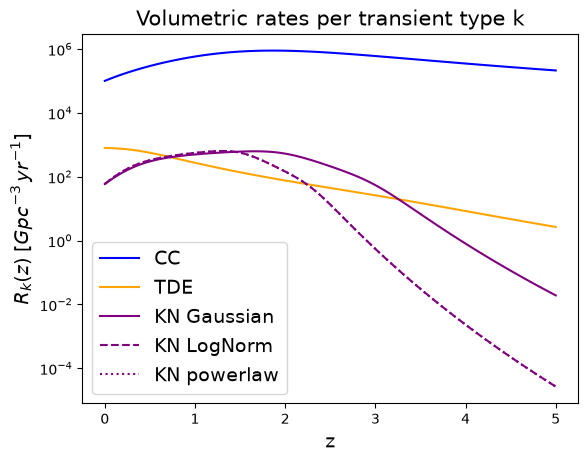

In [2]:
plot_rates()

In [3]:
get_N_k_firesong(R_SFR, R0=p_cosmology['R0']['SN II'], z_max=10)

<Quantity 3.28911644e+08 1 / yr>

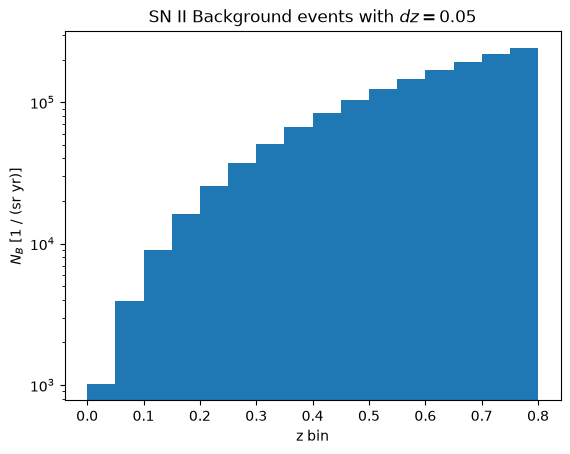

In [32]:
#first for SN II
dz = 0.05
z_range = np.linspace(0, 0.8, int(0.8 / dz) + 1)
bin_centers = (z_range[1:]+z_range[:-1])/2

N_per_bin = []

for z in bin_centers:
    N_z = get_N_k_firesong(R_SFR, R0=p_cosmology['R0']['SN II'], z_max=z) / (4 * np.pi * u.sr)
    N_z_dz = get_N_k_firesong(R_SFR, R0=p_cosmology['R0']['SN II'], z_max=z+dz) / (4 * np.pi * u.sr)
    unit = N_z.unit 
    N_bin = N_z_dz.value - N_z.value
    N_per_bin.append(N_bin)

# N_per_bin = np.array(N_per_bin).value

plt.bar(bin_centers, N_per_bin, width=dz)
plt.yscale('log')
plt.title(rf'SN II Background events with $dz={dz}$')
plt.xlabel('z bin')
plt.ylabel(rf'$N_B$ [{unit}]')
plt.show()

If we assume an area of $A_i=1\;deg^{2}$

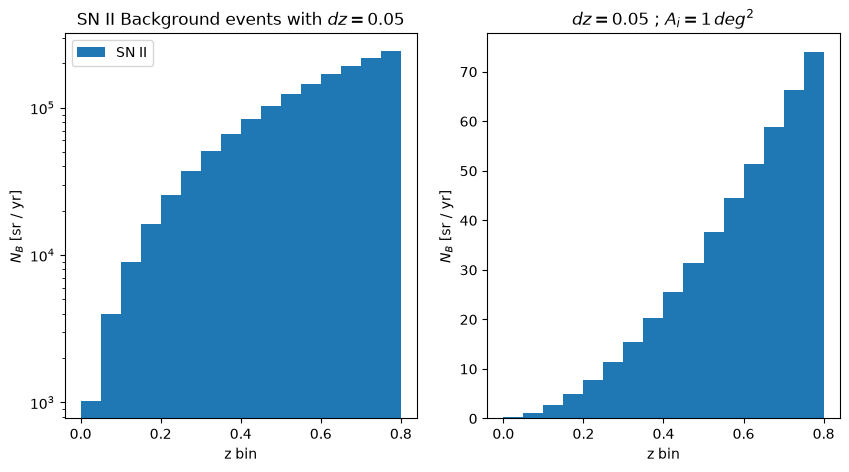

In [34]:
A_i = (1 * u.deg ** 2).to(u.sr)
N_per_bin_in_Ai = np.array(N_per_bin) * unit * A_i

unit = N_per_bin_in_Ai[0].unit


#lets make a combined plot

fig, ax = plt.subplots(1, 2, figsize=(10,5))

ax[0].bar(bin_centers, N_per_bin, width=dz, label='SN II')
ax[0].set_yscale('log')
ax[0].set_title(rf'SN II Background events with $dz={dz}$')
ax[0].set_xlabel('z bin')
ax[0].set_ylabel(rf'$N_B$ [{unit}]')
ax[0].legend()


ax[1].bar(bin_centers, N_per_bin_in_Ai.value, width=dz)
# plt.yscale('log')
ax[1].set_title(rf'$dz={dz}$ ; $A_i=1\,deg^2$')
ax[1].set_xlabel('z bin')
ax[1].set_ylabel(rf'$N_B$ [{unit}]')
plt.show()

Now for all transient types!!

In [54]:
types_k_func ={
    'SN II': R_SFR,
    'SN Ib/c': R_SFR,
    'TDE': R_TDE,
    'sGRB': R_sGRB
}
colors = {
    'SN II': 'darkblue',
    'SN Ib/c': 'blue',
    'TDE': 'darkorange',
    'sGRB': 'green'
}

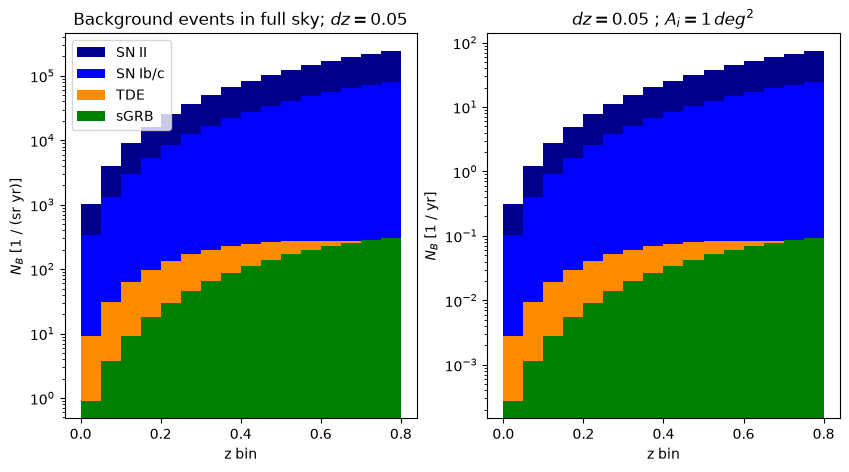

In [57]:

dz = 0.05
z_range = np.linspace(0, 0.8, int(0.8 / dz) + 1)
bin_centers = (z_range[1:]+z_range[:-1])/2

fig, ax = plt.subplots(1, 2, figsize=(10,5))

for type in types_k_func.keys():

    N_per_bin = []

    for z in bin_centers:
        N_z = get_N_k_firesong(types_k_func[type], R0=p_cosmology['R0'][type], z_max=z) / (4 * np.pi * u.sr)
        N_z_dz = get_N_k_firesong(types_k_func[type], R0=p_cosmology['R0'][type], z_max=z+dz) / (4 * np.pi * u.sr)
        unit = N_z.unit 
        N_bin = N_z_dz.value - N_z.value
        N_per_bin.append(N_bin)

    A_i = (1 * u.deg ** 2).to(u.sr)
    N_per_bin_in_Ai = np.array(N_per_bin) * unit * A_i
    



    ax[0].bar(bin_centers, N_per_bin, width=dz, label=type, color=colors[type])
    ax[0].set_yscale('log')
    ax[0].set_title(rf'Background events in full sky; $dz={dz}$')
    ax[0].set_xlabel('z bin')
    ax[0].set_ylabel(rf'$N_B$ [{unit}]')
    

    unit = N_per_bin_in_Ai[0].unit
    ax[1].bar(bin_centers, N_per_bin_in_Ai.value, width=dz, color=colors[type])
    # plt.yscale('log')
    ax[1].set_title(rf'$dz={dz}$ ; $A_i=1\,deg^2$')
    ax[1].set_xlabel('z bin')
    ax[1].set_ylabel(rf'$N_B$ [{unit}]')
    ax[1].set_yscale('log')
ax[0].legend()
plt.savefig('/Users/cristozilleruelo/Desktop/bkg_simple.png')#, bbox_to_inches='tight')
plt.show()


In [ ]:
#should we get the poission probability of this??